# Задача 5: Уравнение окружности в комплексной форме

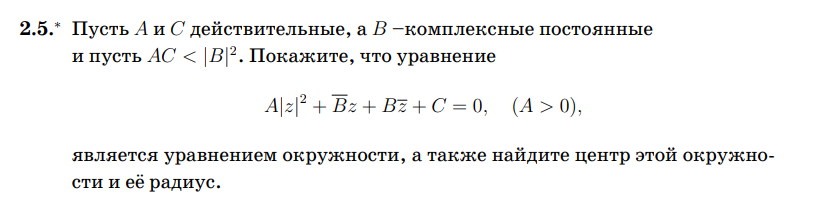

##  Математическая база

### Свойства комплексных чисел

Пусть $z = x + iy$, $\bar{z} = x - iy$. Тогда:

| Тождество | Запись |
|:---:|:---|
| Модуль в квадрате | $|z|^2 = z\bar{z} = x^2 + y^2$ |
| Вещественная часть | $\operatorname{Re}(z) = \frac{z + \bar{z}}{2}$ |
| Мнимая часть | $\operatorname{Im}(z) = \frac{z - \bar{z}}{2i}$ |
| Модуль суммы | $|z + w|^2 = (z+w)(\bar{z}+\bar{w}) = |z|^2 + \bar{w}z + w\bar{z} + |w|^2$ |

### Уравнение окружности

Окружность с центром $z_0$ и радиусом $R$ задаётся уравнением:

$$|z - z_0| = R \quad \Longleftrightarrow \quad (x - x_0)^2 + (y - y_0)^2 = R^2$$

---

## Пошаговое решение

### Условие

Дано уравнение:
$$A|z|^2 + \bar{B}z + B\bar{z} + C = 0, \quad A > 0, \quad AC < |B|^2$$

где $A, C \in \mathbb{R}$, $B \in \mathbb{C}$.

### Решение

**Шаг 1.** Используем тождество $|z|^2 = z\bar{z}$:

$$A z\bar{z} + \bar{B}z + B\bar{z} + C = 0$$

**Шаг 2.** Делим обе части на $A > 0$:

$$z\bar{z} + \frac{\bar{B}}{A}z + \frac{B}{A}\bar{z} + \frac{C}{A} = 0$$

**Шаг 3.** Заметим, что левая часть почти является разложением $|z + w|^2$. Положим $w = \dfrac{B}{A}$, тогда $\bar{w} = \dfrac{\bar{B}}{A}$ и $|w|^2 = \dfrac{|B|^2}{A^2}$.

Прибавляем $\dfrac{|B|^2}{A^2}$ к обеим частям:

$$z\bar{z} + \frac{\bar{B}}{A}z + \frac{B}{A}\bar{z} + \frac{|B|^2}{A^2} = \frac{|B|^2}{A^2} - \frac{C}{A}$$

**Шаг 4.** Левая часть — это точный квадрат:

$$\left(z + \frac{B}{A}\right)\left(\bar{z} + \frac{\bar{B}}{A}\right) = \frac{|B|^2 - AC}{A^2}$$

$$\left|z + \frac{B}{A}\right|^2 = \frac{|B|^2 - AC}{A^2}$$

**Шаг 5.** Так как $AC < |B|^2$ и $A > 0$, правая часть строго положительна:

$$\boxed{\left|z - \left(-\frac{B}{A}\right)\right| = \frac{\sqrt{|B|^2 - AC}}{A}}$$

### Ответ

$$z_0 = -\frac{B}{A}, \qquad R = \frac{\sqrt{|B|^2 - AC}}{A}$$


A = 2.0,  B = (3+4j),  C = 1.0
|B|² = 25.0000,  AC = 2.0000
Условие AC < |B|²: True  ✓

Центр:  z₀ = (-1.5-2j)  (x₀=-1.5000, y₀=-2.0000)
Радиус: R = 2.3979


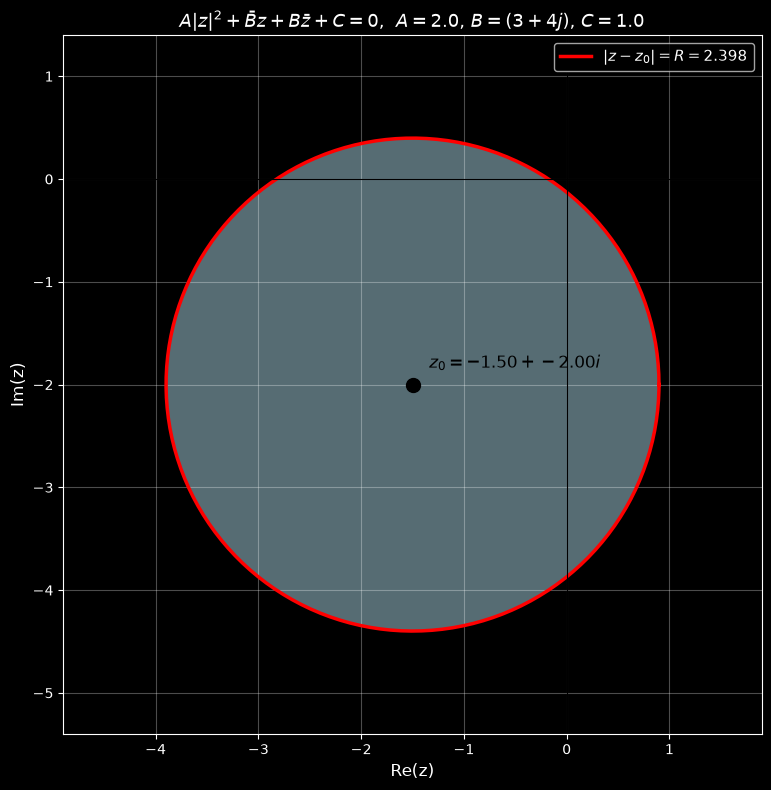

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ─────────────────────────────────────────────────────────
# Параметры задачи (пример)
# ─────────────────────────────────────────────────────────
A = 2.0                          # A > 0
B = 3 + 4j                       # комплексное число, |B|² = 25
C = 1.0                          # вещественное

# Проверка условия AC < |B|²
print(f"A = {A},  B = {B},  C = {C}")
print(f"|B|² = {abs(B)**2:.4f},  AC = {A*C:.4f}")
print(f"Условие AC < |B|²: {A*C < abs(B)**2}  ✓")

# Центр и радиус
z0 = -B / A
R = np.sqrt(abs(B)**2 - A*C) / A
print(f"\nЦентр:  z₀ = {z0}  (x₀={z0.real:.4f}, y₀={z0.imag:.4f})")
print(f"Радиус: R = {R:.4f}")


# ─────────────────────────────────────────────────────────
# Визуализация
# ─────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 8))

# Сетка для проверки знака выражения (внутренность vs внешность)
N = 500
x = np.linspace(z0.real - R - 1, z0.real + R + 1, N)
y = np.linspace(z0.imag - R - 1, z0.imag + R + 1, N)
X, Y = np.meshgrid(x, y)
Z = X + 1j * Y
F = A * np.abs(Z)**2 + np.conj(B)*Z + B*np.conj(Z) + C

# Область, где F < 0 (внутренность окружности)
mask = F < 0
ax.contourf(X, Y, mask, levels=[0.5, 1.5], colors=['lightblue'], alpha=0.5)

# Окружность
theta = np.linspace(0, 2*np.pi, 300)
ax.plot(z0.real + R*np.cos(theta), z0.imag + R*np.sin(theta),
        'r-', linewidth=2.5, label=f'$|z - z_0| = R = {R:.3f}$')

# Центр
ax.plot(z0.real, z0.imag, 'ko', markersize=10)
ax.annotate(f'$z_0 = {z0.real:.2f} + {z0.imag:.2f}i$',
            (z0.real, z0.imag), textcoords="offset points",
            xytext=(12, 12), fontsize=12, color='black')

# Оси
ax.axhline(0, color='black', linewidth=0.8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Re(z)', fontsize=12)
ax.set_ylabel('Im(z)', fontsize=12)
ax.set_title(rf'$A|z|^2 + \bar{{B}}z + B\bar{{z}} + C = 0$,  $A={A}$, $B={B}$, $C={C}$', fontsize=13)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right', fontsize=11)

plt.tight_layout()
plt.savefig('task_2_5.png', dpi=150)
plt.show()